<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h2>تمرین اول کدی یادگیری ماشین</h2>
<p>در این تمرین مدل <span dir="ltr">Linear Regression</span> روی دیتاست قیمت خانه‌های کالیفرنیا پیاده‌سازی شده. مدل به صورت کلاسی در فایل <span dir="ltr">LinearRegression.py</span> نوشته شده و داخل نوت‌بوک با یک <span dir="ltr">Pipeline</span> برای آماده‌سازی داده‌ها استفاده میشه.</p>


</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۱. آماده‌سازی کتابخانه‌ها</h3>
<p>در این بخش کتابخانه‌های لازم برای خواندن داده، آماده‌سازی ویژگی‌ها، آموزش مدل و رسم نمودار وارد میشن.</p>


</div>

In [1]:
import importlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import r2_score

warnings.filterwarnings("ignore")

import LinearRegression as lr_module
importlib.reload(lr_module)
from LinearRegression import LinearRegression


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۲. خواندن داده‌ها</h3>
<p>داده‌ها از فایل <span dir="ltr">housing.csv</span> خوانده میشن. ستون <span dir="ltr">median_house_value</span> خروجی مدل یا همان قیمت خانه‌ست.</p>


</div>

In [2]:
df = pd.read_csv("housing.csv")

print("Dataset shape:", df.shape)
display(df.head())

print("Missing values per column:")
display(df.isna().sum())


Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Missing values per column:


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۳. جدا کردن ورودی و خروجی</h3>
<p>ستون قیمت خانه به عنوان <span dir="ltr">target</span> جدا میشه و بقیه ستون‌ها ورودی مدل هستن. مقدار قیمت‌ها برای پایدارتر شدن آموزش با <span dir="ltr">Gradient Descent</span> تقسیم بر <span dir="ltr">100000</span> شده.</p>


</div>

In [3]:
target_column = "median_house_value"

X = df.drop(columns=[target_column])
y = df[target_column] / 100000.0

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train shape:", X_train_raw.shape)
print("Test shape:", X_test_raw.shape)


Train shape: (16512, 9)
Test shape: (4128, 9)


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۴. ساختن <span dir="ltr">Preprocessing Pipeline</span></h3>
<p>برای ستون‌های عددی مقدارهای خالی با میانه پر میشن و سپس داده‌ها استاندارد میشن. برای ستون‌های متنی هم مقدار خالی با پرتکرارترین مقدار پر میشه و بعد از <span dir="ltr">One-Hot Encoding</span> استفاده میشه.</p>


</div>

In [4]:
numeric_features = X_train_raw.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train_raw.select_dtypes(include=["object"]).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("Transformed train shape:", X_train.shape)
print("Transformed test shape:", X_test.shape)


Transformed train shape: (16512, 13)
Transformed test shape: (4128, 13)


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۵. نام ویژگی‌های نهایی</h3>
<p>بعد از <span dir="ltr">One-Hot Encoding</span> تعداد ستون‌ها تغییر می‌کنه. برای بررسی وزن‌ها، نام ویژگی‌های نهایی ذخیره میشه.</p>


</div>

In [5]:
def get_feature_names(preprocessor, numeric_features, categorical_features):
    feature_names = list(numeric_features)

    if len(categorical_features) > 0:
        encoder = preprocessor.named_transformers_["cat"].named_steps["encoder"]
        encoded_names = encoder.get_feature_names_out(categorical_features).tolist()
        feature_names.extend(encoded_names)

    return feature_names

feature_names = get_feature_names(preprocessor, numeric_features, categorical_features)
print("Number of final features:", len(feature_names))
print(feature_names)


Number of final features: 13
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۶. کلاس <span dir="ltr">Linear Regression</span></h3>
<p>کلاس مدل در فایل <span dir="ltr">LinearRegression.py</span> کامل شده. این کلاس دو حالت آموزش داره: <span dir="ltr">gradient_descent</span> و <span dir="ltr">normal_equation</span>.</p>


</div>

In [6]:
model_check = LinearRegression(method="gradient_descent")
print(model_check.__dict__)


{'method': 'gradient_descent', 'weights': None, 'bias': None, 'loss_history': []}


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۷. تابع‌های ارزیابی</h3>
<p>برای مقایسه مدل‌ها از <span dir="ltr">RMSE</span> و <span dir="ltr">R2</span> استفاده میشه. چون خروجی موقع آموزش مقیاس‌بندی شده، مقدار <span dir="ltr">RMSE</span> دوباره به دلار تبدیل میشه.</p>


</div>

In [7]:
def rmse(y_true, y_pred):
    return np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2))


def evaluate_model(model, X_train, y_train, X_test, y_test):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    return {
        "Train RMSE ($)": rmse(y_train, train_pred) * 100000,
        "Test RMSE ($)": rmse(y_test, test_pred) * 100000,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred)
    }


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۸. بخش الف: آموزش با <span dir="ltr">Gradient Descent</span></h3>
<p>مدل با چند مقدار مختلف برای <span dir="ltr">Learning Rate</span> آموزش داده میشه تا اثر آن روی کاهش <span dir="ltr">Loss</span> مشخص بشه. گرادیان‌ها داخل کلاس به صورت دستی حساب شدن.</p>


</div>

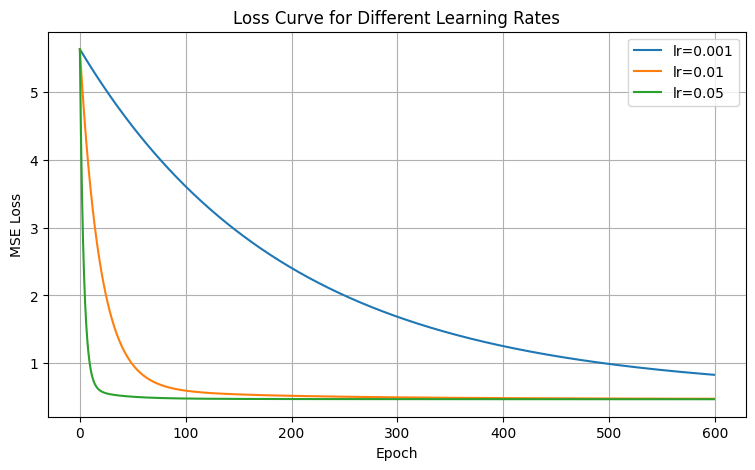

,Train RMSE ($),Test RMSE ($),Train R2,Test R2,Learning Rate,Final Loss
0,91028.814760,91652.233002,0.380133,0.358969,0.001,0.829881
1,69041.161040,70335.518118,0.643420,0.622478,0.010,0.476693
2,68526.134591,69982.527354,0.648720,0.626258,0.050,0.469585


In [8]:
learning_rates = [0.001, 0.01, 0.05]
epochs = 600

gd_models = {}
gd_results = []

plt.figure(figsize=(9, 5))

for lr in learning_rates:
    model = LinearRegression(method="gradient_descent")
    model.fit(X_train, y_train, epochs=epochs, learning_rate=lr)
    gd_models[lr] = model

    metrics = evaluate_model(model, X_train, y_train, X_test, y_test)
    metrics["Learning Rate"] = lr
    metrics["Final Loss"] = model.loss_history[-1]
    gd_results.append(metrics)

    plt.plot(model.loss_history, label=f"lr={lr}")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Loss Curve for Different Learning Rates")
plt.legend()
plt.grid(True)
plt.show()

gd_results_df = pd.DataFrame(gd_results)
display(gd_results_df)


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۹. انتخاب مدل بهتر در <span dir="ltr">Gradient Descent</span></h3>
<p>از بین مدل‌های بخش قبل، مدلی که کمترین خطای تست رو داره به عنوان مدل بهتر انتخاب میشه.</p>


</div>

In [9]:
best_lr = gd_results_df.sort_values("Test RMSE ($)").iloc[0]["Learning Rate"]
best_gd_model = gd_models[best_lr]

print("Best learning rate:", best_lr)
print("Best Gradient Descent bias:", best_gd_model.bias)

best_gd_weights = pd.DataFrame({
    "Feature": feature_names,
    "Weight": best_gd_model.weights
})

display(best_gd_weights.head(10))


Best learning rate: 0.05
Best Gradient Descent bias: 1.6877350606546169


,Feature,Weight
0,longitude,-0.465855
1,latitude,-0.469868
2,housing_median_age,0.139736
3,total_rooms,-0.114330
4,total_bedrooms,0.363354
5,population,-0.441503
6,households,0.242454
7,median_income,0.748362
8,ocean_proximity_<1H OCEAN,0.523029
9,ocean_proximity_INLAND,0.079073


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۱۰. بخش ب: آموزش با <span dir="ltr">Normal Equation</span></h3>
<p>در این روش وزن‌ها به صورت مستقیم از روی رابطه ماتریسی به دست میان و دیگر نیازی به <span dir="ltr">Epoch</span> و <span dir="ltr">Learning Rate</span> نیست.</p>


</div>

In [10]:
normal_model = LinearRegression(method="normal_equation")
normal_model.fit(X_train, y_train)

normal_results = evaluate_model(normal_model, X_train, y_train, X_test, y_test)
normal_results_df = pd.DataFrame([normal_results])
display(normal_results_df)

normal_weights = pd.DataFrame({
    "Feature": feature_names,
    "Weight": normal_model.weights
})

display(normal_weights.head(10))


,Train RMSE ($),Test RMSE ($),Train R2,Test R2
0,68433.937367,70059.193339,0.649665,0.625438


,Feature,Weight
0,longitude,-0.538266
1,latitude,-0.544157
2,housing_median_age,0.138899
3,total_rooms,-0.130943
4,total_bedrooms,0.430682
5,population,-0.434034
6,households,0.183822
7,median_income,0.751678
8,ocean_proximity_<1H OCEAN,0.208778
9,ocean_proximity_INLAND,-0.189088


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۱۱. بررسی <span dir="ltr">pinv</span> و <span dir="ltr">inv</span></h3>
<p>در این بخش، روش <span dir="ltr">torch.linalg.inv</span> و <span dir="ltr">torch.linalg.pinv</span> برای حل <span dir="ltr">Normal Equation</span> مقایسه میشن. هدف اینه که مشخص بشه چرا برای این داده استفاده از <span dir="ltr">pinv</span> انتخاب مطمئن‌تریه.</p>


</div>

In [11]:
X_train_bias = np.c_[np.ones(X_train.shape[0]), X_train]
X_test_bias = np.c_[np.ones(X_test.shape[0]), X_test]

X_train_torch = torch.tensor(X_train_bias, dtype=torch.float64)
X_test_torch = torch.tensor(X_test_bias, dtype=torch.float64)
y_train_torch = torch.tensor(y_train.to_numpy(), dtype=torch.float64)

rank = torch.linalg.matrix_rank(X_train_torch).item()
columns = X_train_torch.shape[1]
condition_x = torch.linalg.cond(X_train_torch).item()
condition_xtx = torch.linalg.cond(X_train_torch.T @ X_train_torch).item()

theta_pinv = torch.linalg.pinv(X_train_torch) @ y_train_torch

try:
    theta_inv = torch.linalg.inv(X_train_torch.T @ X_train_torch) @ X_train_torch.T @ y_train_torch
    inv_status = "computed"
    max_theta_diff = torch.max(torch.abs(theta_inv - theta_pinv)).item()

    pred_inv = (X_test_torch @ theta_inv).numpy()
    inv_test_rmse = rmse(y_test, pred_inv) * 100000
except RuntimeError:
    theta_inv = None
    inv_status = "failed"
    max_theta_diff = np.nan
    inv_test_rmse = np.nan

pred_pinv = (X_test_torch @ theta_pinv).numpy()
pinv_test_rmse = rmse(y_test, pred_pinv) * 100000

pinv_inv_check = pd.DataFrame({
    "Item": [
        "Number of columns",
        "Matrix rank",
        "Condition number of X",
        "Condition number of X.T @ X",
        "inv status",
        "Max |theta_inv - theta_pinv|",
        "Test RMSE with inv ($)",
        "Test RMSE with pinv ($)"
    ],
    "Value": [
        columns,
        rank,
        condition_x,
        condition_xtx,
        inv_status,
        max_theta_diff,
        inv_test_rmse,
        pinv_test_rmse
    ]
})

display(pinv_inv_check)


,Item,Value
0,Number of columns,14
1,Matrix rank,13
2,Condition number of X,1003391295810980.25
3,Condition number of X.T @ X,70739945536413880.0
4,inv status,computed
5,Max |theta_inv - theta_pinv|,17.635932
6,Test RMSE with inv ($),609949.006466
7,Test RMSE with pinv ($),70059.193339


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>نتیجه بخش <span dir="ltr">pinv</span> و <span dir="ltr">inv</span></h3>
<p>طبق نتایج بالا، رتبه ماتریس از تعداد ستون‌ها کمتره و عدد شرطی هم مقدار خیلی بزرگی داره. این یعنی ماتریس از نظر عددی وضعیت پایداری نداره و بعضی ستون‌ها می‌تونن به هم وابسته باشن. در این حالت استفاده از <span dir="ltr">inv</span> ممکنه جواب ناپایدار بده یا حتی در بعضی اجراها خطا ایجاد کنه.</p>
<p>به همین دلیل استفاده از <span dir="ltr">pinv</span> مناسب‌تره، چون برای مسئله‌های <span dir="ltr">least squares</span> حتی وقتی ماتریس وارون‌پذیر نباشه هم می‌تونه جواب قابل استفاده‌ای بده. در این آزمایش هم خطای مدل با <span dir="ltr">pinv</span> بهتر شده، پس برای پیاده‌سازی <span dir="ltr">Normal Equation</span> از همین روش استفاده شد.</p>


</div>

<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۱۲. مقایسه وزن‌های دو روش</h3>
<p>در این بخش وزن‌های مدل به‌دست‌اومده از <span dir="ltr">Gradient Descent</span> و <span dir="ltr">Normal Equation</span> کنار هم قرار می‌گیرن. اگر آموزش <span dir="ltr">Gradient Descent</span> خوب همگرا شده باشه، وزن‌ها باید به جواب مستقیم نزدیک باشن.</p>


</div>

In [12]:
weight_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Gradient Descent Weight": best_gd_model.weights,
    "Normal Equation Weight": normal_model.weights,
})

weight_comparison["Absolute Difference"] = np.abs(
    weight_comparison["Gradient Descent Weight"] - weight_comparison["Normal Equation Weight"]
)

bias_comparison = pd.DataFrame({
    "Parameter": ["Bias"],
    "Gradient Descent": [best_gd_model.bias],
    "Normal Equation": [normal_model.bias],
    "Absolute Difference": [abs(best_gd_model.bias - normal_model.bias)]
})

print("Bias comparison:")
display(bias_comparison)

print("Top weight differences:")
display(weight_comparison.sort_values("Absolute Difference", ascending=False).head(10))

weight_l2_difference = np.linalg.norm(best_gd_model.weights - normal_model.weights)
print("L2 difference between weight vectors:", weight_l2_difference)


Bias comparison:


,Parameter,Gradient Descent,Normal Equation,Absolute Difference
0,Bias,1.687735,1.99022,0.302485


Top weight differences:


,Feature,Gradient Descent Weight,Normal Equation Weight,Absolute Difference
10,ocean_proximity_ISLAND,0.029157,1.570029,1.540872
12,ocean_proximity_NEAR OCEAN,0.572805,0.243090,0.329715
11,ocean_proximity_NEAR BAY,0.483671,0.157412,0.326260
8,ocean_proximity_<1H OCEAN,0.523029,0.208778,0.314251
9,ocean_proximity_INLAND,0.079073,-0.189088,0.268162
1,latitude,-0.469868,-0.544157,0.074289
0,longitude,-0.465855,-0.538266,0.072411
4,total_bedrooms,0.363354,0.430682,0.067328
6,households,0.242454,0.183822,0.058632
3,total_rooms,-0.114330,-0.130943,0.016613


L2 difference between weight vectors: 1.6670888587977837


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۱۳. مقایسه نتیجه نهایی</h3>
<p>در آخر، خطای مدل انتخاب‌شده از بخش <span dir="ltr">Gradient Descent</span> با مدل <span dir="ltr">Normal Equation</span> مقایسه میشه.</p>


</div>

In [13]:
final_comparison = []

gd_metrics = evaluate_model(best_gd_model, X_train, y_train, X_test, y_test)
gd_metrics["Method"] = f"Gradient Descent (lr={best_lr})"
final_comparison.append(gd_metrics)

ne_metrics = evaluate_model(normal_model, X_train, y_train, X_test, y_test)
ne_metrics["Method"] = "Normal Equation"
final_comparison.append(ne_metrics)

final_comparison_df = pd.DataFrame(final_comparison)
final_comparison_df = final_comparison_df[[
    "Method",
    "Train RMSE ($)",
    "Test RMSE ($)",
    "Train R2",
    "Test R2"
]]

display(final_comparison_df)


,Method,Train RMSE ($),Test RMSE ($),Train R2,Test R2
0,Gradient Descent (lr=0.05),68526.134591,69982.527354,0.648720,0.626258
1,Normal Equation,68433.937367,70059.193339,0.649665,0.625438


<div dir="rtl" style="text-align: right; line-height: 1.9; font-family: Tahoma, Arial, sans-serif; font-size: 15px;">


<h3>۱۴. جمع‌بندی</h3>
<p>مدل <span dir="ltr">Gradient Descent</span> با محاسبه دستی گرادیان‌ها آموزش داده شد و نمودار کاهش <span dir="ltr">Loss</span> برای چند مقدار <span dir="ltr">Learning Rate</span> رسم شد. سپس مدل با <span dir="ltr">Normal Equation</span> هم آموزش داده شد و نتیجه دو روش از نظر خطا و وزن‌ها مقایسه شد. برای بخش <span dir="ltr">Normal Equation</span> هم از <span dir="ltr">pinv</span> استفاده شد، چون در این داده نسبت به <span dir="ltr">inv</span> جواب پایدارتر و مناسب‌تری میده.</p>


</div>